# October 2026 PCE, build

In [1]:
import os, sys, inspect, warnings
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
warnings.filterwarnings('ignore')
sys.dont_write_bytecode = True

def find_subtask():
    here = os.path.abspath('')
    for c in (here, os.path.join(here, '02_Research', 'Subtasks', '04_oct_pce_build'), os.path.dirname(here)):
        if os.path.exists(os.path.join(c, 'code', 'D_common.py')):
            return c
    raise FileNotFoundError('Open this notebook from 02_Research/Subtasks/04_oct_pce_build/')

SUB = find_subtask()
OUT = os.path.join(SUB, 'outputs')
sys.path.insert(0, os.path.join(SUB, 'code'))
import D_common as dc

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 60)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

def check(label, live, saved, tol=5e-5):
    ok = abs(live - saved) <= tol
    print(f"{'MATCH ' if ok else 'DIFFERS'}  {label}: live {live:.4f} | audited file {saved:.4f}")

def show_source(fn):
    print(inspect.getsource(fn))

print('Subtask folder:', SUB)

Subtask folder: ./02_Research/Subtasks/04_oct_pce_build


## 0. Inputs


In [2]:
HIST_NOV11 = os.path.join(OUT, 'component_series_history_2026-11-11.csv')
HIST_NOV13 = os.path.join(OUT, 'component_series_history.csv')

def make_engine(history_file):
    dc.HISTORY = history_file          # the engine reads its CPI/PPI history from this file
    return dc.Engine()

eng_oct = make_engine(HIST_NOV13)      # October 2026 estimate
eng_bt = make_engine(HIST_NOV11)       # backtest, on the audited inputs

inputs = pd.DataFrame([
    ('BEA Table 2.4.4U-D, "Price Indexes for PCE: Source Data"', 'which CPI/PPI BEA uses for each PCE line, and its seasonal status', 'table dated 2026-09-30 (plus the Feb 2026 and Feb 2025 versions for older months)'),
    ('BEA underlying detail U20404 / U20405', 'PCE price index and nominal spending for every line', 'vintage 2026-11-10 (data through Sep 2026)'),
    ('BLS API: 284 CPI and PPI component series', 'the October inputs and their history', 'Nov 11 pull (backtest); Nov 13 pull (adds October PPI)'),
    ('ALFRED: PCEPILFE, PCEPI, CPILFESL', 'what BEA and BLS first published each month', 'all vintages, retrieved 2026-11-11'),
    ('BLS PPI Detailed Reports (archived PDFs)', 'first-release portfolio-management PPIs', 'Nov 2025 – Jul 2026 reports'),
    ('Cleveland Fed inflation nowcast', 'benchmark', 'chart files as of 2026-11-10'),
], columns=['source', 'used for', 'vintage'])
display(inputs)

h13 = pd.read_csv(HIST_NOV13)
ppi = h13[h13.series_id.str.startswith(('PCU', 'WPU'))]
last = ppi.dropna(subset=['value']).assign(m=lambda d: d.year.astype(str) + '-' + d.period.str[1:]).groupby('series_id').m.max()
print(f'PPI series with an October 2026 value in the Nov 13 snapshot: {(last == "2026-10").sum()} of {len(last)}')

,source,used for,vintage
0,"BEA Table 2.4.4U-D, ""Price Indexes for PCE: Source Data""","which CPI/PPI BEA uses for each PCE line, and its season...",table dated 2026-09-30 (plus the Feb 2026 and Feb 2025 v...
1,BEA underlying detail U20404 / U20405,PCE price index and nominal spending for every line,vintage 2026-11-10 (data through Sep 2026)
2,BLS API: 284 CPI and PPI component series,the October inputs and their history,Nov 11 pull (backtest); Nov 13 pull (adds October PPI)
3,"ALFRED: PCEPILFE, PCEPI, CPILFESL",what BEA and BLS first published each month,"all vintages, retrieved 2026-11-11"
4,BLS PPI Detailed Reports (archived PDFs),first-release portfolio-management PPIs,Nov 2025 – Jul 2026 reports
5,Cleveland Fed inflation nowcast,benchmark,chart files as of 2026-11-10


PPI series with an October 2026 value in the Nov 13 snapshot: 28 of 28


## 2. The component map


In [3]:
T = '2026-10'
wc_saved = pd.read_csv(os.path.join(OUT, 'backtest_window_choice.csv'))
K = int(wc_saved[wc_saved.chosen & (wc_saved.measure == 'core')].window.iloc[0])   # carry-forward window (section 7 re-derives it)
version = dc.table_version(T)
summ_oct, df_oct = eng_oct.estimate(T, k=K, version=version)

def line_type(r):
    cat = r['cat']
    if cat == 'assumed':
        return '5. Carried forward (assumed)'
    if cat == 'proxied':
        return '4. Proxied'
    if cat == 'blend':
        ws = str(r['weight_source'])
        how = 'CPI relative importance' if 'relative' in ws else ('fitted on BEA history' if 'fitted' in ws else 'equal weights (fallback)')
        return f'3. Composite, weights: {how}'
    src = 'CPI' if str(r['inputs']).startswith('CU') else 'PPI'
    if cat == 'observed_needs_seasonal':
        return f'2. {src} direct, needs our seasonal adjustment'
    return f'1. {src} direct, used as published'

df_oct['type'] = df_oct.apply(line_type, axis=1)
df_oct['our_seasonal_adj'] = (df_oct.seasonal == 'SAbyBEA') & (df_oct.cat != 'assumed')

def source_of(r):
    if r['cat'] == 'assumed':
        return 'Carried forward (no October data)'
    if r['cat'] == 'proxied':
        return 'Proxied'
    if r['cat'] == 'blend':
        return 'Composite'
    return 'CPI direct' if str(r['inputs']).startswith('CU') else 'PPI direct'

df_oct['source'] = df_oct.apply(source_of, axis=1)
def handling(r):
    if r['cat'] == 'assumed':
        return 'n/a'
    st = r['seasonal']
    if st == 'SAbyBEA':
        return 'our own adjustment'
    if st == 'SA':
        return 'BLS-adjusted'
    if st == 'NSA':
        return 'unadjusted, as BEA does'
    # composites: BEA states the status per input; CUSR = BLS seasonally adjusted, everything else unadjusted
    ins = str(r['inputs']).split(';')
    sa_flags = {i.startswith('CUSR') for i in ins}
    if sa_flags == {True}:
        return 'BLS-adjusted'
    if sa_flags == {False}:
        return 'unadjusted, as BEA does'
    return 'mixed (some inputs BLS-adjusted, some unadjusted)'

df_oct['seasonal handling'] = df_oct.apply(handling, axis=1)

rows_order = ['CPI direct', 'PPI direct', 'Composite', 'Proxied', 'Carried forward (no October data)']
cols_order = ['BLS-adjusted', 'unadjusted, as BEA does', 'our own adjustment', 'mixed (some inputs BLS-adjusted, some unadjusted)', 'n/a']

def grid(weight_col):
    g = pd.pivot_table(df_oct, index='source', columns='seasonal handling', values=weight_col, aggfunc='sum', fill_value=0) * 100
    g = g.reindex(index=rows_order, columns=cols_order, fill_value=0)
    g['total'] = g.sum(axis=1)
    g.loc['total'] = g.sum()
    return g

counts = pd.pivot_table(df_oct, index='source', columns='seasonal handling', values='line', aggfunc='count', fill_value=0)
counts = counts.reindex(index=rows_order, columns=cols_order, fill_value=0)
counts['total'] = counts.sum(axis=1); counts.loc['total'] = counts.sum()

fmt = lambda v: '' if abs(v) < 0.05 else f'{v:.1f}%'
print('Share of CORE spending (%)')
display(grid('w_c').style.format(fmt))
print('Share of HEADLINE spending (%)')
display(grid('w_h').style.format(fmt))
print('Number of lines')
display(counts.style.format(lambda v: '' if v == 0 else f'{v:.0f}'))

own = df_oct['seasonal handling'] == 'our own adjustment'
print(f"Rests on our own seasonal adjustment: {100 * df_oct.loc[own, 'w_c'].sum():.1f}% of core, "
      f"{100 * df_oct.loc[own, 'w_h'].sum():.1f}% of headline ({int(own.sum())} lines).")

Share of CORE spending (%)


seasonal handling,BLS-adjusted,"unadjusted, as BEA does",our own adjustment,"mixed (some inputs BLS-adjusted, some unadjusted)",n/a,total
source,,,,,,
CPI direct,35.5%,29.4%,0.3%,,,65.3%
PPI direct,,1.1%,18.6%,,,19.7%
Composite,,1.2%,2.2%,,,3.4%
Proxied,0.2%,,,,,0.2%
Carried forward (no October data),,,,,11.4%,11.4%
total,35.7%,31.7%,21.1%,,11.4%,100.0%


Share of HEADLINE spending (%)


seasonal handling,BLS-adjusted,"unadjusted, as BEA does",our own adjustment,"mixed (some inputs BLS-adjusted, some unadjusted)",n/a,total
source,,,,,,
CPI direct,39.6%,27.8%,0.3%,,,67.7%
PPI direct,,1.0%,16.5%,,,17.5%
Composite,,1.1%,1.9%,1.5%,,4.5%
Proxied,0.1%,,,,,0.1%
Carried forward (no October data),,,,,10.2%,10.2%
total,39.7%,29.8%,18.8%,1.5%,10.2%,100.0%


Number of lines


seasonal handling,BLS-adjusted,"unadjusted, as BEA does",our own adjustment,"mixed (some inputs BLS-adjusted, some unadjusted)",n/a,total
source,,,,,,
CPI direct,78,77,3,,,158
PPI direct,,10,11,,,21
Composite,,2,3,2,,7
Proxied,1,,,,,1
Carried forward (no October data),,,,,25,25
total,79,89,17,2,25,212


Rests on our own seasonal adjustment: 21.1% of core, 18.8% of headline (17 lines).


## 3. Pricing every line, October 2026

In [4]:
t = dc.P(T)
specs_oct = eng_oct.specs(version)

def row(ln):
    return df_oct[df_oct.line == ln].iloc[0]

def head_tail(d, n=5):
    print(f'{len(d)} lines, sorted by headline weight (top {n} and bottom {n} shown)' if len(d) > 2 * n else f'{len(d)} lines')
    display(pd.concat([d.head(n), d.tail(n)]) if len(d) > 2 * n else d)

def check_group(d, label):
    eng_pi = df_oct.set_index('line').loc[d['line'], 'pi'].values
    print(f"{'MATCH ' if np.allclose(d['Oct m/m %'].values, eng_pi, atol=1e-9) else 'DIFFERS'}  {label}: every line equals the engine's value")

def weights(d):
    w = df_oct.set_index('line').loc[d['line']]
    d['headline weight'] = w.w_h.values
    d['core weight'] = w.w_c.values
    d['contribution to core (pp)'] = d['core weight'] * d['Oct m/m %']
    d['contribution to headline (pp)'] = d['headline weight'] * d['Oct m/m %']
    return d.sort_values('headline weight', ascending=False).reset_index(drop=True)

### 3a. Direct: one CPI or PPI series, used as published

In [5]:
rows = []
for r in df_oct[df_oct.cat.isin(['observed_published', 'proxied'])].itertuples():
    sid = r.inputs
    lv = eng_oct.src_lv[sid]
    pi, how = eng_oct.series_mm(sid, t)
    rows.append({'line': r.line, 'name': r.name, 'series': sid, 'type': 'CPI' if sid.startswith('CU') else 'PPI',
                 'Sep level': lv.get(t - 1), 'Oct level': lv.get(t), 'Oct m/m %': pi,
                 'note': ('proxied (farm rent on OER)' if r.cat == 'proxied' else '') + ('2-month change (Sep not published)' if '2-month' in how else '')})
direct = weights(pd.DataFrame(rows))
print(direct.type.value_counts().to_string(), '\n')
check_group(direct, 'direct lines')

# BLS's own published 1-month % change (BLS API, calculations=true; pulled 2026-11-13) next to ours
import json
raw = json.load(open(os.path.join(SUB, '..', '..', '..', '03_Data', 'Raw', 'bls_api_direct_pct_changes_2026-11-13.json')))
bls_pct = {}
for resp in raw:
    for s in resp['Results']['series']:
        for o in s['data']:
            if o['year'] == '2026' and o['period'] == 'M10' and o.get('calculations', {}).get('pct_changes', {}).get('1') not in (None, '', '-'):
                bls_pct[s['seriesID']] = float(o['calculations']['pct_changes']['1'])
direct['BLS published m/m %'] = direct.series.map(bls_pct)
direct['ours, rounded'] = (direct['Oct m/m %'] + 1e-9).round(1)
direct['same?'] = np.where(direct['BLS published m/m %'].isna(), 'n/a', np.where(direct['ours, rounded'] == direct['BLS published m/m %'], 'yes', 'NO'))
cols = ['line', 'name', 'series', 'Sep level', 'Oct level', 'Oct m/m %', 'ours, rounded', 'BLS published m/m %', 'same?', 'core weight']
display(pd.concat([direct[cols].head(3), direct[cols].tail(3)]))
cmp = direct[direct['same?'] != 'n/a']
print(f"All direct lines: ours rounded to one decimal equals BLS's published change for {(cmp['same?'] == 'yes').sum()} of {len(cmp)} lines "
      f"({len(direct) - len(cmp)} have no BLS one-month change, e.g. a series published every other month).")
if (cmp['same?'] == 'NO').any():
    display(cmp[cmp['same?'] == 'NO'][cols])

type
CPI    156
PPI     10 

MATCH   direct lines: every line equals the engine's value


,line,name,series,Sep level,Oct level,Oct m/m %,"ours, rounded",BLS published m/m %,same?,core weight
0,162,Owner-occupied stationary homes,CUSR0000SEHC01,445.1950,446.5880,0.3129,0.3000,0.3000,yes,0.1289
1,157,Tenant-occupied stationary homes,CUSR0000SEHA,450.4290,451.3370,0.2016,0.2000,0.2000,yes,0.0398
2,123,Prescription drugs,CUUR0000SEMF01,543.5560,545.2900,0.3190,0.3000,0.3000,yes,0.0311
163,314,Repair and hire of footwear,CUUR0000SEGD04,313.2860,319.2020,1.8884,1.9000,1.9000,yes,0.0000
164,51,"Calculators, typewriters, and other information processi...",CUSR0000SEEE04,83.2860,83.7120,0.5115,0.5000,0.5000,yes,0.0000
165,16,Employee reimbursement,CUSR0000SETA04,167.8520,158.2760,-5.7050,-5.7000,-5.7000,yes,-0.0001


All direct lines: ours rounded to one decimal equals BLS's published change for 164 of 164 lines (2 have no BLS one-month change, e.g. a series published every other month).


### 3b. Our own seasonal adjustment: deriving BEA's October factor, then applying it

In [6]:
# Lines BEA adjusts itself ("SA by BEA"): 14 single-series lines here, plus 3 composites in 3c.
# Our October factor for a line = average over past Octobers of (BEA's adjusted change - the unadjusted source change).
sabea = df_oct[(df_oct.seasonal == 'SAbyBEA') & (df_oct.cat != 'assumed')].sort_values('w_h', ascending=False)
rows = {}
for r in sabea.itertuples():
    spec = specs_oct[r.line]
    gap = eng_oct.bea_mm[r.line] - eng_oct.nsa_source_hist(spec, t)
    adj, yrs = eng_oct.method_b(spec, t)
    yr = {int(y) for y in yrs.split(',')} if yrs else set()
    rows[f'{r.line} {r.name[:34]}'] = {**{str(y): gap.get(dc.P(f'{y}-10')) for y in range(2017, 2026) if y in yr},
                                      'October factor (average)': adj}
factors = pd.DataFrame(rows).T
print("Gap in each past October (BEA's adjusted change minus the unadjusted source change, pp); the factor is their average")
display(factors)

# Applied to October 2026: all 17 lines, same order as the table above.
rows = []
for r in sabea.itertuples():
    spec = specs_oct[r.line]
    w, _ = eng_oct.blend_weights(spec, t)
    unadj = float(np.dot(w, [eng_oct.series_mm(s_, t)[0] for s_, _ in spec['inputs']]))
    adj, _ = eng_oct.method_b(spec, t)
    rows.append({'line': r.line, 'name': r.name, 'source': r.inputs if len(spec['inputs']) == 1 else 'composite (inputs in 3c)',
                 'unadjusted Oct m/m %': unadj, 'October factor (pp)': adj, 'Oct m/m % (= unadjusted + factor)': unadj + adj})
own_sa = weights(pd.DataFrame(rows).rename(columns={'Oct m/m % (= unadjusted + factor)': 'Oct m/m %'}))
print('Applied to October 2026: October m/m = unadjusted October change + October factor')
display(own_sa)
print(f"Total: {len(own_sa)} lines, {100 * own_sa['core weight'].sum():.1f}% of core, contribution to core {own_sa['contribution to core (pp)'].sum():+.4f} pp")
check_group(own_sa, 'own-seasonal-adjustment lines')


Gap in each past October (BEA's adjusted change minus the unadjusted source change, pp); the factor is their average


,2017,2018,2019,2020,2021,2022,2023,2024,2025,October factor (average)
184 Nonprofit hospitals' services to h,-0.4538,-0.4264,-0.3612,-0.2407,-0.2708,-0.2946,-0.3415,-0.4436,-0.5178,-0.3723
174 Physician services,0.0400,0.0682,0.0029,0.0068,0.0028,0.0027,0.0032,0.0019,0.0029,0.0146
186 Government hospitals,-0.4527,-0.4264,-0.3611,-0.2407,-0.2699,-0.2946,-0.3423,-0.4428,-0.5170,-0.3720
276 Medical care and hospitalization,0.0678,0.0843,0.2240,0.2134,0.1802,0.2296,0.2803,0.3093,0.3173,0.2118
50 Computer software and accessories,NaN,NaN,NaN,NaN,-0.2772,-0.0124,0.2013,-0.0883,NaN,-0.0441
207 Air transportation,-4.4286,-4.5400,-4.3652,-7.2371,-6.3338,-6.1965,-8.1888,-6.5821,-5.7765,-5.9610
177 Home health care,-0.2956,-0.2691,-0.3233,-0.4265,-0.4060,-0.3130,-0.2538,-0.2387,-0.2413,-0.3075
189 Proprietary and government nursing,-0.5268,-0.5632,-0.6139,-0.6043,-0.5989,-0.7223,-0.7686,-0.8096,-0.8432,-0.6723
185 Proprietary hospitals,-0.4528,-0.4274,-0.3612,-0.2407,-0.2699,-0.2946,-0.3415,-0.4428,-0.5171,-0.3720
299 Legal services,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.1323,0.0626,-0.0349


Applied to October 2026: October m/m = unadjusted October change + October factor


,line,name,source,unadjusted Oct m/m %,October factor (pp),Oct m/m %,headline weight,core weight,contribution to core (pp),contribution to headline (pp)
0,184,Nonprofit hospitals' services to households,PCU622---622---,0.6770,-0.3723,0.3047,0.0534,0.0601,0.0183,0.0163
1,174,Physician services,PCU6211--6211--,0.0444,0.0146,0.0590,0.0399,0.0449,0.0026,0.0024
2,186,Government hospitals,PCU622---622---,0.6770,-0.3720,0.3051,0.0162,0.0182,0.0056,0.0049
3,276,Medical care and hospitalization,PCU524114524114,0.0238,0.2118,0.2356,0.0118,0.0133,0.0031,0.0028
4,50,Computer software and accessories,composite (inputs in 3c),-1.6501,-0.0441,-1.6943,0.0112,0.0126,-0.0213,-0.0190
5,207,Air transportation,PCU4811114811111,3.6207,-5.9610,-2.3402,0.0106,0.0120,-0.0280,-0.0249
6,177,Home health care,PCU621610621610,0.2471,-0.3075,-0.0603,0.0105,0.0119,-0.0007,-0.0006
7,189,Proprietary and government nursing homes,PCU623110623110,0.4998,-0.6723,-0.1726,0.0095,0.0106,-0.0018,-0.0016
8,185,Proprietary hospitals,PCU622---622---,0.6770,-0.3720,0.3050,0.0091,0.0102,0.0031,0.0028
9,299,Legal services,composite (inputs in 3c),-0.1475,-0.0349,-0.1824,0.0075,0.0085,-0.0015,-0.0014


Total: 17 lines, 21.1% of core, contribution to core -0.0232 pp
MATCH   own-seasonal-adjustment lines: every line equals the engine's value


### 3c. Composites: several series combined with weights

The three composites that also need our seasonal factor (software, legal services, professional dues) are counted in 3b; the other four are counted here.

In [7]:
rows = []
for r in df_oct[df_oct.cat == 'blend'].itertuples():
    spec = specs_oct[r.line]
    w, how = eng_oct.blend_weights(spec, t)
    mms = [eng_oct.series_mm(s, t)[0] for s, _ in spec['inputs']]
    combined = float(np.dot(w, mms))
    adj = eng_oct.method_b(spec, t)[0] if spec['seasonal'] == 'SAbyBEA' else 0.0
    rows.append({'line': r.line, 'name': r.name,
                 'inputs (weight, Oct m/m %)': '; '.join(f'{s} ({wi:.2f}, {m:+.2f})' for (s, _), wi, m in zip(spec['inputs'], w, mms)),
                 'weights from': how.split(' on ')[0].replace('fitted NNLS sum-to-one', 'fitted on BEA history'),
                 'combined m/m %': combined, 'our October factor (pp)': adj, 'Oct m/m %': combined + adj})
comp = weights(pd.DataFrame(rows))
head_tail(comp)
check_group(comp, 'composite lines')

7 lines


,line,name,"inputs (weight, Oct m/m %)",weights from,combined m/m %,our October factor (pp),Oct m/m %,headline weight,core weight,contribution to core (pp),contribution to headline (pp)
0,95,"Food products, not elsewhere classified","CUSR0000SEFT04 (0.18, +0.19); CUSR0000SEFT01 (0.05, -0.9...",CPI relative importance Dec 2025,0.7974,0.0000,0.7974,0.0117,0.0000,0.0000,0.0093
1,50,Computer software and accessories,"CUUR0000SEEE02 (0.63, -1.53); PCU5132105132107 (0.16, -3...",fitted on BEA history,-1.6501,-0.0441,-1.6943,0.0112,0.0126,-0.0213,-0.0190
2,285,Cellular telephone services,"CUUR0000SEED03 (0.78, -0.16); CUUR0000SSEE041 (0.22, +1.35)",fitted on BEA history,0.1756,0.0000,0.1756,0.0080,0.0090,0.0016,0.0014
3,299,Legal services,"PCU5411105411103 (0.20, -0.52); PCU541110541110C (0.20, ...",equal (fallback: only 21 obs),-0.1475,-0.0349,-0.1824,0.0075,0.0085,-0.0015,-0.0014
4,87,Processed dairy products,"CUUR0000SEFJ02 (0.46, +1.32); CUSR0000SEFJ03 (0.20, +1.0...",CPI relative importance Dec 2025,1.1731,0.0000,1.1731,0.0034,0.0000,0.0000,0.0040
5,178,Medical laboratories,"PCU621511621511 (0.51, +0.01); PCU621512621512 (0.49, -0...",fitted on BEA history,-0.0201,0.0000,-0.0201,0.0025,0.0029,-0.0001,-0.0001
6,305,Professional association dues,"PCU5411105411103 (0.20, -0.52); PCU541110541110C (0.20, ...",equal (fallback: only 21 obs),-0.1475,-0.0366,-0.1841,0.0007,0.0008,-0.0001,-0.0001


MATCH   composite lines: every line equals the engine's value


#### How the composite weights are chosen




Line 95 Food products, not elsewhere classified  ->  rule 1: CPI relative importance


,input,"relative importance share (Dec 2025, rescaled)"
0,CUSR0000SEFT04,0.1849
1,CUSR0000SEFT01,0.0496
2,CUSR0000SEFT02,0.1779
3,CUSR0000SEFT03,0.2170
4,CUUR0000SEFT05,0.0309
5,CUUR0000SEFT06,0.3396



Line 50 Computer software and accessories  ->  rule 2: fitted

Line 285 Cellular telephone services  ->  rule 2: fitted

Line 299 Legal services  ->  rule 3: equal weights

Line 87 Processed dairy products  ->  rule 1: CPI relative importance


,input,"relative importance share (Dec 2025, rescaled)"
0,CUUR0000SEFJ02,0.4595
1,CUSR0000SEFJ03,0.2025
2,CUSR0000SEFJ04,0.3380



Line 178 Medical laboratories  ->  rule 2: fitted

Line 305 Professional association dues  ->  rule 3: equal weights

Rules 2 and 3: the weight fit (12-month % change of the composite vs BEA's index for the line)


,line,name,months of history,sample,weights,R² fitted weights,R² equal weights,same as engine,result
0,50,Computer software and accessories,57,2022-01 to 2026-09,"CUUR0000SEEE02: 0.63, PCU5132105132107: 0.16, PCU5182105...",0.9599,0.4844,yes,NaN
1,285,Cellular telephone services,70,2020-12 to 2026-09,"CUUR0000SEED03: 0.78, CUUR0000SSEE041: 0.22",0.8041,-13.2793,yes,NaN
2,299,Legal services,21,NaN,"PCU5411105411103: 0.20, PCU541110541110C: 0.20, PCU54111...",NaN,NaN,NaN,fewer than 24 -> equal weights
3,178,Medical laboratories,105,2018-01 to 2026-09,"PCU621511621511: 0.51, PCU621512621512: 0.49",0.9998,0.9996,yes,NaN
4,305,Professional association dues,21,NaN,"PCU5411105411103: 0.20, PCU541110541110C: 0.20, PCU54111...",NaN,NaN,NaN,fewer than 24 -> equal weights


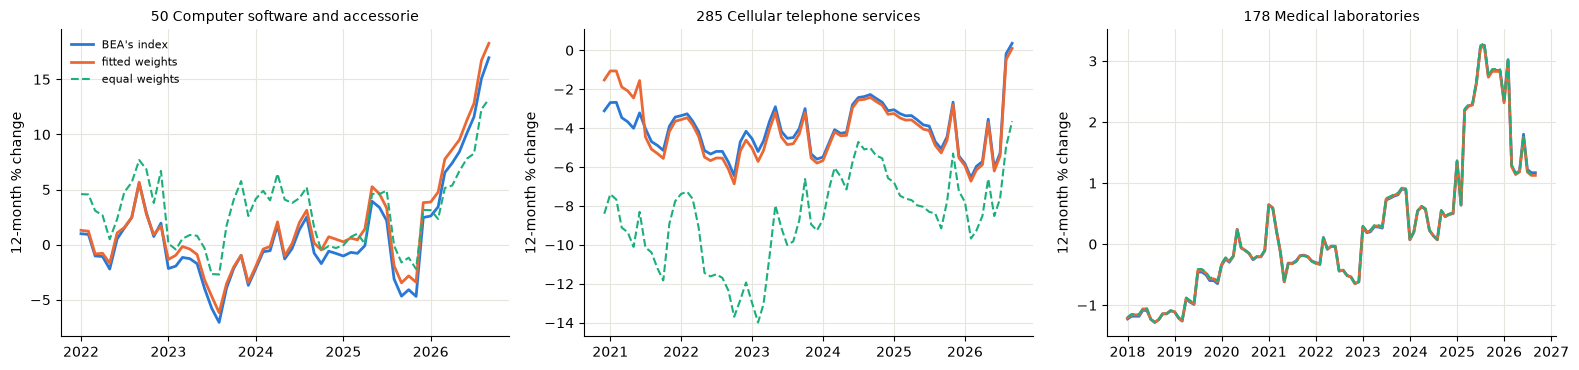

In [8]:
from scipy.optimize import nnls
import matplotlib.pyplot as plt

for ln in comp.sort_values('headline weight', ascending=False).line:
    spec = specs_oct[ln]
    w, how = eng_oct.blend_weights(spec, t)
    rule = spec['weight_rule']
    print(f"\nLine {ln} {spec['name']}  ->  {'rule 1: CPI relative importance' if rule == 'RI' else ('rule 3: equal weights' if how.startswith('equal') else 'rule 2: fitted')}")
    if rule == 'RI':
        display(pd.DataFrame({'input': [s for s, _ in spec['inputs']], 'relative importance share (Dec 2025, rescaled)': w}))

fit_lines = [ln for ln in comp.line if specs_oct[ln]['weight_rule'] == 'fit']
fit_rows, curves = [], {}
for ln in fit_lines:
    spec = specs_oct[ln]
    ids = [s for s, _ in spec['inputs']]
    start, end = dc.fit_sample_start(ln, dc.P('2017-01')), t - 1
    y = 100 * np.log(eng_oct.bea_p[ln]).diff(12)
    X = pd.concat([100 * np.log(eng_oct.src_lv[s]).diff(12) for s in ids], axis=1); X.columns = ids
    d = pd.concat([y.rename('BEA'), X], axis=1).loc[start:end].dropna()
    w_eng, how = eng_oct.blend_weights(spec, t)
    if len(d) < 24:
        fit_rows.append({'line': ln, 'name': spec['name'], 'months of history': len(d), 'result': 'fewer than 24 -> equal weights',
                         'weights': ', '.join(f'{s}: {x:.2f}' for s, x in zip(ids, w_eng))})
        continue
    A = np.vstack([d[ids].values, 1e4 * np.ones((1, len(ids)))]); b = np.concatenate([d['BEA'].values, [1e4]])
    w_fit, _ = nnls(A, b, maxiter=5000); w_fit = w_fit / w_fit.sum()       # same calculation as the engine
    comp_fit = d[ids].values @ w_fit; comp_eq = d[ids].values.mean(axis=1)
    r2 = lambda p_: 1 - ((d['BEA'] - p_) ** 2).sum() / ((d['BEA'] - d['BEA'].mean()) ** 2).sum()
    fit_rows.append({'line': ln, 'name': spec['name'], 'months of history': len(d), 'sample': f'{d.index[0]} to {d.index[-1]}',
                     'weights': ', '.join(f'{s}: {x:.2f}' for s, x in zip(ids, w_fit)),
                     'R² fitted weights': r2(comp_fit), 'R² equal weights': r2(comp_eq),
                     'same as engine': 'yes' if np.allclose(w_fit, w_eng, atol=1e-6) else 'NO'})
    curves[ln] = (spec['name'], d.index.to_timestamp(), d['BEA'], comp_fit, comp_eq)
print('\nRules 2 and 3: the weight fit (12-month % change of the composite vs BEA\'s index for the line)')
display(pd.DataFrame(fit_rows))

fig, ax = plt.subplots(1, len(curves), figsize=(5.3 * len(curves), 3.8))
for a, (ln, (name, x, bea, fit_, eq_)) in zip(np.atleast_1d(ax), curves.items()):
    a.plot(x, bea, color='#2a78d6', linewidth=2, label="BEA's index")
    a.plot(x, fit_, color='#eb6834', linewidth=2, label='fitted weights')
    a.plot(x, eq_, color='#1baf7a', linewidth=1.5, linestyle='--', label='equal weights')
    a.set_title(f'{ln} {name[:32]}', fontsize=10); a.set_ylabel('12-month % change')
    a.grid(color='#e6e5e0', linewidth=0.8); a.set_axisbelow(True)
    for s_ in ('top', 'right'): a.spines[s_].set_visible(False)
np.atleast_1d(ax)[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### Testing our seasonal factors: Dec 2025 – Sep 2026

17 lines x 10 months = 170 observations
Regression of BEA's actual change on ours, weighted by core share:  slope 0.536, intercept +0.167, R^2 0.661
   same, using the unadjusted source (no factor):                  slope 0.459, intercept +0.207, R^2 0.525
   unweighted, all lines (dominated by tax preparation's swings):  slope 0.357, R^2 0.483


,,core weight,MAE with our factor,MAE unadjusted,mean miss (bias)
line,name,,,,
184,Nonprofit hospitals' services to households,0.0596,0.0882,0.1755,-0.0104
174,Physician services,0.0449,0.0180,0.0896,0.0020
186,Government hospitals,0.0182,0.0884,0.1757,-0.0104
276,Medical care and hospitalization,0.0134,0.1948,0.4969,0.0240
50,Computer software and accessories,0.0124,0.2957,0.3240,0.2403
177,Home health care,0.0118,0.0535,0.1105,-0.0414
207,Air transportation,0.0110,1.1397,1.8094,0.1093
189,Proprietary and government nursing homes,0.0106,0.1353,0.2037,-0.0246
185,Proprietary hospitals,0.0101,0.0882,0.1753,-0.0103


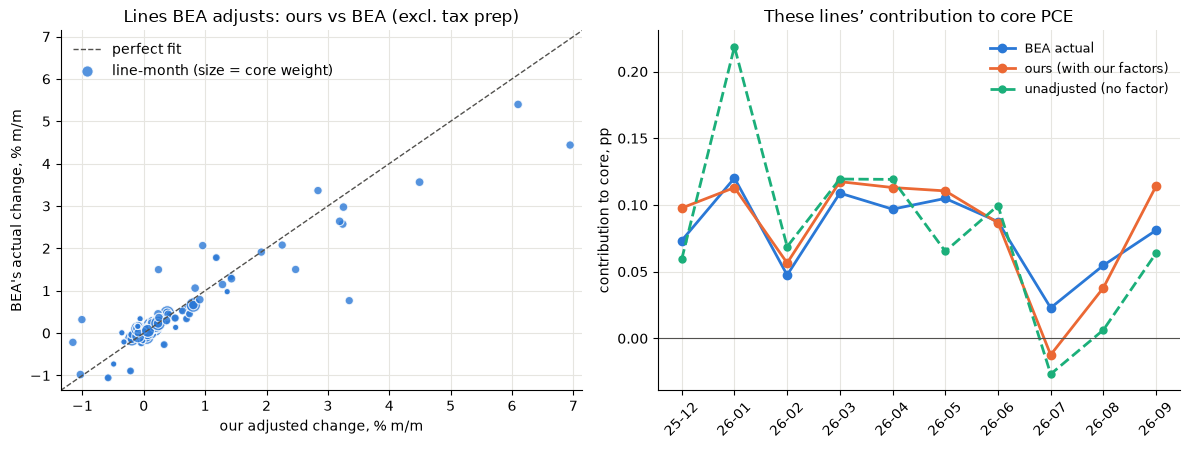

Contribution to core, ours minus BEA: MAE 0.0157 pp, bias +0.0037 pp; without our factors: MAE 0.0333 pp.


In [9]:
import matplotlib.pyplot as plt
BLUE, ORANGE, AQUA, INK, MUTED = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e'

# For each month, for every line BEA adjusts itself: our adjusted change (unadjusted source + our factor for that
# calendar month, estimated from earlier years only) vs BEA's actual change for the line (current vintage).
# Current BEA source table throughout, so this tests the seasonal method itself on today's definitions.
cur = eng_bt.specs('2026-09-30')
test_lines = [ln for ln, s in cur.items() if s['seasonal'] == 'SAbyBEA' and s['tier'] != 'assumed']
recs = []
for m in dc.RULE_MONTHS:
    tm = dc.P(m)
    wts = eng_bt.estimate(m, k=K, version='2026-09-30')[1].set_index('line')
    for ln in test_lines:
        spec = cur[ln]
        w, _ = eng_bt.blend_weights(spec, tm)
        mms = [eng_bt.series_mm(s, tm, first_release=False)[0] for s, _ in spec['inputs']]
        if any(pd.isna(x) for x in mms):
            continue
        raw = float(np.dot(w, mms))
        adj = eng_bt.method_b(spec, tm)[0]
        recs.append({'month': m, 'line': ln, 'name': spec['name'], 'core weight': wts.at[ln, 'w_c'],
                     'unadjusted': raw, 'factor': adj, 'ours (adjusted)': raw + adj, 'BEA actual': eng_bt.bea_mm.at[tm, ln]})
sf = pd.DataFrame(recs)
sf['miss'] = sf['ours (adjusted)'] - sf['BEA actual']

# Weighted by each line's share of core, so the lines that matter for core count most.
fit_w = smf.wls('Q("BEA actual") ~ Q("ours (adjusted)")', data=sf, weights=sf['core weight']).fit()
fit_w_raw = smf.wls('Q("BEA actual") ~ unadjusted', data=sf, weights=sf['core weight']).fit()
fit_u = smf.ols('Q("BEA actual") ~ Q("ours (adjusted)")', data=sf).fit()
ex_air = sf[sf.line != 301]     # tax preparation left off the chart: off-scale noise, 0.3% of core
print(f"{sf.line.nunique()} lines x {sf.month.nunique()} months = {len(sf)} observations")
print(f"Regression of BEA's actual change on ours, weighted by core share:  slope {fit_w.params.iloc[1]:.3f}, intercept {fit_w.params.iloc[0]:+.3f}, R^2 {fit_w.rsquared:.3f}")
print(f"   same, using the unadjusted source (no factor):                  slope {fit_w_raw.params.iloc[1]:.3f}, intercept {fit_w_raw.params.iloc[0]:+.3f}, R^2 {fit_w_raw.rsquared:.3f}")
print(f"   unweighted, all lines (dominated by tax preparation's swings):  slope {fit_u.params.iloc[1]:.3f}, R^2 {fit_u.rsquared:.3f}")

per_line = (sf.groupby(['line', 'name'])
            .apply(lambda d: pd.Series({'core weight': d['core weight'].mean(), 'MAE with our factor': d['miss'].abs().mean(),
                                        'MAE unadjusted': (d['unadjusted'] - d['BEA actual']).abs().mean(),
                                        'mean miss (bias)': d['miss'].mean()}))
            .sort_values('core weight', ascending=False))
display(per_line)

monthly = sf.assign(our_c=sf['core weight'] * sf['ours (adjusted)'], bea_c=sf['core weight'] * sf['BEA actual'],
                    raw_c=sf['core weight'] * sf['unadjusted']).groupby('month')[['our_c', 'bea_c', 'raw_c']].sum()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for a in ax:
    a.grid(color='#e6e5e0', linewidth=0.8); a.set_axisbelow(True)
    for s in ('top', 'right'): a.spines[s].set_visible(False)
# 1. ours vs BEA, every line-month
lim = [min(ex_air['ours (adjusted)'].min(), ex_air['BEA actual'].min()) - 0.2, max(ex_air['ours (adjusted)'].max(), ex_air['BEA actual'].max()) + 0.2]
ax[0].plot(lim, lim, color=MUTED, linewidth=1, linestyle='--', label='perfect fit')
ax[0].scatter(ex_air['ours (adjusted)'], ex_air['BEA actual'], s=20 + 1500 * ex_air['core weight'], color=BLUE, alpha=0.8, edgecolor='white', linewidth=0.8, label='line-month (size = core weight)')
ax[0].set(xlim=lim, ylim=lim, xlabel='our adjusted change, % m/m', ylabel="BEA's actual change, % m/m",
          title='Lines BEA adjusts: ours vs BEA (excl. tax prep)')
ax[0].legend(frameon=False, loc='upper left')
# 2. what it means for core
x = range(len(monthly))
ax[1].plot(x, monthly.bea_c, color=BLUE, linewidth=2, marker='o', markersize=6, label="BEA actual")
ax[1].plot(x, monthly.our_c, color=ORANGE, linewidth=2, marker='o', markersize=6, label='ours (with our factors)')
ax[1].plot(x, monthly.raw_c, color=AQUA, linewidth=2, linestyle='--', marker='o', markersize=5, label='unadjusted (no factor)')
ax[1].axhline(0, color=MUTED, linewidth=0.8)
ax[1].set_xticks(list(x)); ax[1].set_xticklabels([m[2:] for m in monthly.index], rotation=45)
ax[1].set(ylabel='contribution to core, pp', title='These lines’ contribution to core PCE')
ax[1].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

d_ = monthly.our_c - monthly.bea_c
print(f"Contribution to core, ours minus BEA: MAE {d_.abs().mean():.4f} pp, bias {d_.mean():+.4f} pp; "
      f"without our factors: MAE {(monthly.raw_c - monthly.bea_c).abs().mean():.4f} pp.")

### 3d. Carried forward: no October data, so the average of BEA's own monthly change over the last 12 months

In [11]:
rows = []
for r in df_oct[df_oct.cat == 'assumed'].itertuples():
    bl = 156 if r.line == 157 else r.line
    rows.append({'line': r.line, 'name': r.name, 'Oct m/m %': eng_oct.carry_forward(bl, t, K),
                 'why': 'source not published for October' if 'source missing' in str(r.note) else 'no replicable October input'})
carry = weights(pd.DataFrame(rows))
head_tail(carry)
check_group(carry, 'carried-forward lines')

25 lines, sorted by headline weight (top 5 and bottom 5 shown)


,line,name,Oct m/m %,why,headline weight,core weight,contribution to core (pp),contribution to headline (pp)
0,342,NPISH final consumption (leaf),0.0738,no replicable October input,0.0297,0.0334,0.0025,0.0022
1,268,Portfolio management and investment advice services,0.6586,no replicable October input,0.0170,0.0191,0.0126,0.0112
2,255,Commercial banks,0.4059,no replicable October input,0.0125,0.0141,0.0057,0.0051
3,256,Other depository institutions and regulated investment c...,0.0840,no replicable October input,0.0120,0.0135,0.0011,0.0010
4,320,Individual and family services,0.3395,no replicable October input,0.0061,0.0069,0.0023,0.0021
20,323,"Other social assistance, not elsewhere classified",0.2166,no replicable October input,0.0004,0.0004,0.0001,0.0001
21,330,"Repair of furniture, furnishings, and floor coverings",0.7227,no replicable October input,0.0001,0.0001,0.0001,0.0001
22,130,Film and photographic supplies,-0.5942,no replicable October input,0.0001,0.0001,-0.0000,-0.0000
23,220,Photo processing,-0.0699,no replicable October input,0.0001,0.0001,-0.0000,-0.0000
24,103,Food produced and consumed on farms,-0.3732,no replicable October input,0.0000,0.0000,-0.0000,-0.0000


MATCH   carried-forward lines: every line equals the engine's value


### All lines together

In [12]:
comp_other = comp[~comp.line.isin(own_sa.line)]
groups = {'3a direct': direct, '3b own seasonal adjustment (incl. 3 composites)': own_sa, '3c other composites': comp_other, '3d carried forward': carry}
summary = pd.DataFrame({g: {'lines': len(d), 'headline weight %': 100 * d['headline weight'].sum(), 'core weight %': 100 * d['core weight'].sum(),
                            'contribution to core (pp)': d['contribution to core (pp)'].sum(),
                            'contribution to headline (pp)': d['contribution to headline (pp)'].sum()} for g, d in groups.items()}).T
summary.loc['total'] = summary.sum()
display(summary)
print(f"Lines priced: {int(summary.loc['total', 'lines'])} of {len(df_oct)}")

# October 2026 rates: extend BEA's published SA September index (vintage Oct 29) by our October change.
# 3-month annualized = (I_Oct / I_Jul)^4 - 1, 6-month annualized = (I_Oct / I_Apr)^2 - 1, 12-month = I_Oct / I_Oct2025 - 1.
# Band on the monthly change = the larger of the bottom-up band and the first-release variant's backtest RMSE (Eli, Nov 13);
# an October error is magnified about 4x in the 3-month rate, 2x in the 6-month, 1x in the 12-month.
band_a, _ = dc.bottom_up_band(eng_oct, df_oct, T)
var_saved = pd.read_csv(os.path.join(OUT, 'D2_backtest_variant_first_release_pm.csv'))
rmse_v = {m_: var_saved.query("row_type == 'summary' and run == 'variant' and group == 'rule (Dec 2025-Sep 2026)' and measure == @m_").rmse.iloc[0]
          for m_ in ('core', 'headline')}
rates_tab = {}
for meas, sid, ba in (('core', 'PCEPILFE', band_a['band_a_c']), ('headline', 'PCEPI', band_a['band_a_h'])):
    vint, lvls = dc.base_vintage_levels(sid, t)
    r_ = dc.rates(lvls, t, summ_oct[meas])
    b_ = max(ba, rmse_v[meas])
    rates_tab[f'{meas} PCE'] = {'month-over-month %': f"{r_['r1m']:.2f} ± {b_:.2f}",
                                '3-month annualized %': f"{r_['r3m_ann']:.2f} ± {4 * b_:.2f}",
                                '6-month annualized %': f"{r_['r6m_ann']:.2f} ± {2 * b_:.2f}",
                                '12-month %': f"{r_['r12m']:.2f} ± {b_:.2f}"}
print('\nOctober 2026')
display(pd.DataFrame(rates_tab))
saved = pd.read_csv(os.path.join(OUT, 'D_build_2026-10_summary.csv')).set_index('measure')
check('core m/m vs the saved build', summ_oct['core'], saved.loc['core', 'estimate_mm'])
check('headline m/m vs the saved build', summ_oct['headline'], saved.loc['headline', 'estimate_mm'])
check('core band vs the saved build', max(band_a['band_a_c'], rmse_v['core']), saved.loc['core', 'band_reported'])
clev = pd.read_csv(os.path.join(OUT, 'cleveland_nowcast_history.csv')).query("target_month == '2026-10'").iloc[0]
print(f"For reference, Cleveland Fed nowcast (Nov 10): core {clev.core_pce_nowcast_on_cpi_day:.2f} m/m, headline {clev.pce_nowcast_on_cpi_day:.2f} m/m")

,lines,headline weight %,core weight %,contribution to core (pp),contribution to headline (pp)
3a direct,166.0000,68.4931,66.2428,0.2854,0.2959
3b own seasonal adjustment (incl. 3 composites),17.0000,18.7751,21.1318,-0.0232,-0.0206
3c other composites,4.0000,2.5639,1.1862,0.0015,0.0147
3d carried forward,25.0000,10.1679,11.4392,0.0314,0.0279
total,212.0000,100.0000,100.0000,0.2951,0.3179


Lines priced: 212 of 212



October 2026


,core PCE,headline PCE
month-over-month %,0.30 ± 0.05,0.32 ± 0.05
3-month annualized %,3.55 ± 0.20,4.62 ± 0.18
6-month annualized %,2.95 ± 0.10,3.09 ± 0.09
12-month %,3.24 ± 0.05,3.82 ± 0.05


MATCH   core m/m vs the saved build: live 0.2951 | audited file 0.2951
MATCH   headline m/m vs the saved build: live 0.3179 | audited file 0.3179
MATCH   core band vs the saved build: live 0.0489 | audited file 0.0489
For reference, Cleveland Fed nowcast (Nov 10): core 0.27 m/m, headline 0.31 m/m


## 4. Comparing against alternatives, Dec 2025 – Sep 2026

Each month, every method's estimate of core PCE m/m against what BEA **first** published. Our model is the first-release variant (Eli, Nov 13).

- **Core CPI alone**: regress core PCE on core CPI, re-estimated each month on earlier data only.
- **Cleveland Fed nowcast**: its last core PCE nowcast before BEA's release.
- **Last month**: assume core PCE repeats last month's first print.

,BEA first print,our model,core CPI alone,Cleveland Fed nowcast,last month
month,,,,,
2025-12,0.3554,0.3795,0.2125,0.2333,0.1604
2026-01,0.3635,0.2806,0.2559,0.2707,0.3554
2026-02,0.3669,0.3886,0.2033,0.2317,0.3635
2026-03,0.2932,0.2919,0.1908,0.2302,0.3669
2026-04,0.2389,0.2664,0.3143,0.2947,0.2932
2026-05,0.3201,0.3646,0.1996,0.2367,0.2389
2026-06,0.1322,0.1738,0.0485,0.1870,0.3201
2026-07,0.2455,0.2025,0.2067,0.2472,0.1322
2026-08,0.2474,0.3037,0.2560,0.2744,0.2455


,MAE,SE of MAE,RMSE,bias,months closest to BEA
our model,0.0423,0.0081,0.0489,0.0169,5
core CPI alone,0.0874,0.0159,0.0995,-0.0706,1
Cleveland Fed nowcast,0.0677,0.0131,0.0783,-0.0398,1
last month,0.0788,0.0221,0.1030,-0.0156,3


MATCH   our model core MAE vs the audited backtest: live 0.0423 | audited file 0.0423


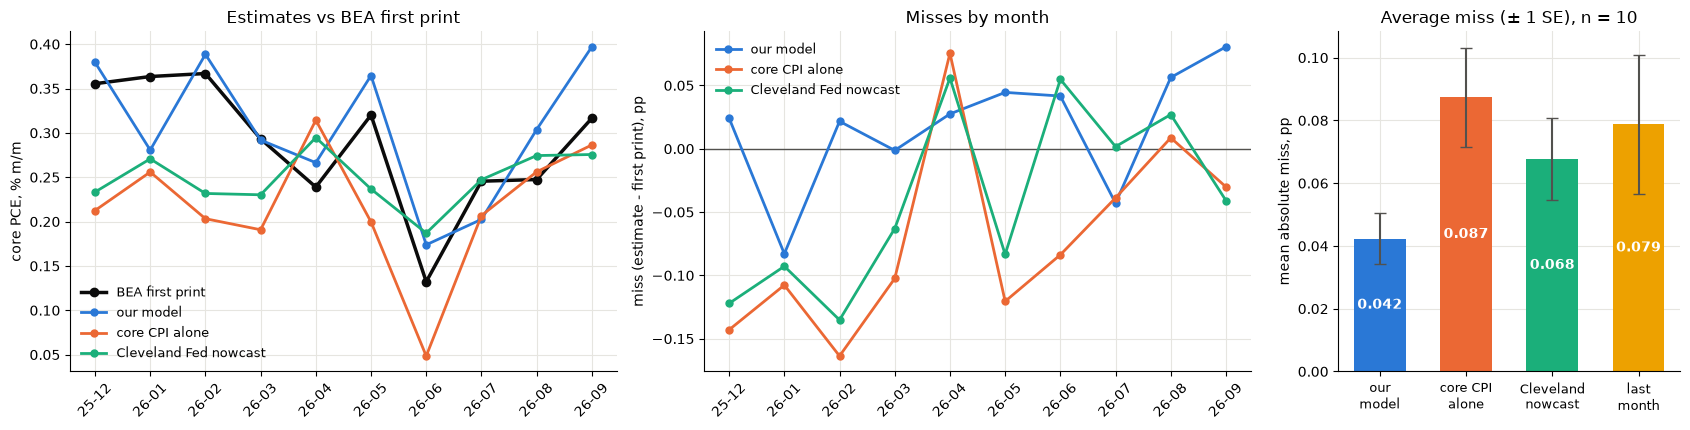

In [13]:
from D_backtest import core_cpi_current, bench_core_cpi_ols, cleveland
from D2_variant_first_release_pm import PMSwapEngine
dc.HISTORY = HIST_NOV11
eng_var = PMSwapEngine(swap=True)
fps = dc.first_prints()
cpi_mm, cpi_mm_f = core_cpi_current()

rows = []
for m in dc.RULE_MONTHS:
    fp = fps[('core', m)]
    rows.append({'month': m, 'BEA first print': fp['mm'],
                 'our model': eng_var.estimate(m, k=K, version=dc.table_version(m))[0]['core'],
                 'core CPI alone': bench_core_cpi_ols(eng_bt, m, cpi_mm, cpi_mm_f)[0],
                 'Cleveland Fed nowcast': cleveland(m, fp['vintage'])[0],
                 'last month': fps[('core', str(dc.P(m) - 1))]['mm']})
bt = pd.DataFrame(rows).set_index('month')
display(bt)

methods = ['our model', 'core CPI alone', 'Cleveland Fed nowcast', 'last month']
miss = bt[methods].sub(bt['BEA first print'], axis=0)
scores = pd.DataFrame({'MAE': miss.abs().mean(), 'SE of MAE': miss.abs().std(ddof=1) / np.sqrt(len(miss)),
                       'RMSE': np.sqrt((miss ** 2).mean()), 'bias': miss.mean(),
                       'months closest to BEA': miss.abs().idxmin(axis=1).value_counts().reindex(methods, fill_value=0)})
display(scores)
mae_var_saved = var_saved.query("row_type == 'summary' and run == 'variant' and measure == 'core' and group == 'rule (Dec 2025-Sep 2026)'").mae.iloc[0]
check('our model core MAE vs the audited backtest', scores.loc['our model', 'MAE'], mae_var_saved)

COL = {'our model': '#2a78d6', 'core CPI alone': '#eb6834', 'Cleveland Fed nowcast': '#1baf7a', 'last month': '#eda100'}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4), gridspec_kw={'width_ratios': [1.6, 1.6, 1]})
for a in ax:
    a.grid(color='#e6e5e0', linewidth=0.8); a.set_axisbelow(True)
    for s_ in ('top', 'right'): a.spines[s_].set_visible(False)
x = np.arange(len(bt)); labels = [m[2:] for m in bt.index]
ax[0].plot(x, bt['BEA first print'], color='#0b0b0b', linewidth=2.5, marker='o', markersize=6, label='BEA first print')
for mth in methods[:3]:
    ax[0].plot(x, bt[mth], color=COL[mth], linewidth=2, marker='o', markersize=5, label=mth)
ax[0].set_xticks(x); ax[0].set_xticklabels(labels, rotation=45)
ax[0].set(ylabel='core PCE, % m/m', title='Estimates vs BEA first print')
ax[0].legend(frameon=False, fontsize=9)
ax[1].axhline(0, color='#52514e', linewidth=1)
for mth in methods[:3]:
    ax[1].plot(x, miss[mth], color=COL[mth], linewidth=2, marker='o', markersize=5, label=mth)
ax[1].set_xticks(x); ax[1].set_xticklabels(labels, rotation=45)
ax[1].set(ylabel='miss (estimate - first print), pp', title='Misses by month')
ax[1].legend(frameon=False, fontsize=9)
bars = ax[2].bar(range(len(methods)), scores['MAE'], yerr=scores['SE of MAE'], capsize=4, ecolor='#52514e', width=0.6,
                 color=[COL[m_] for m_ in methods])
for b_, v in zip(bars, scores['MAE']):
    ax[2].text(b_.get_x() + b_.get_width() / 2, v / 2, f'{v:.3f}', ha='center', va='center', fontsize=10, color='white', fontweight='bold')
ax[2].set_xticks(range(len(methods))); ax[2].set_xticklabels(['our\nmodel', 'core CPI\nalone', 'Cleveland\nnowcast', 'last\nmonth'], fontsize=9)
ax[2].set(ylabel='mean absolute miss, pp', title='Average miss (± 1 SE), n = 10')
plt.tight_layout(); plt.show()